# Bloc 4 — Faire tourner wyat (19 min)

**Situation.** Le modèle est branché sur le jeu **dev**. Une seule modification de texte, l'option facturation raccourcie en *« Facturation : questions sur les factures »*, suffit à envoyer *« vous m'avez débité 9,99 € »* chez *autre*. Personne n'a touché au modèle.

Vous n'avez qu'à **exécuter les cellules dans l'ordre** (Maj+Entrée). On travaille sur le jeu **dev** (63 messages synthétiques étiquetés ; 20 en *mode rapide* sur un PC sans GPU) : ici on a le droit de regarder les erreurs et de modifier les options.

Une barre de progression et une durée estimée s'affichent pendant les calculs. Une décision déjà calculée sur votre ordinateur n'est pas recalculée.

In [1]:
# Préparation (rien à modifier) — exécutez avec Maj+Entrée
import sys; sys.path.insert(0, "..")   # le paquet atelier/ (installé par installer.sh ; ceci au cas où)
import matplotlib.pyplot as plt
import pandas as pd
import wyat
import atelier as at                  # même boîte à outils que la commande `atelier` et les exemples/
pd.set_option("display.max_colwidth", 90)
modele = at.charger_modele()

Modèle chargé en 2.1 s  (backend=mlx, device=gpu-apple, id=fork-197dbfe273512031109…)
Vitesse mesurée : ≈ 0.16 s par message.


## 1. Les options actuelles (le « contrat » donné au modèle)

In [2]:
pd.Series(at.OPTIONS, name="description lue par le modèle")

facturation    Facturation et paiements : montant d'une facture, débits ou prélèvements bancaires, re...
technique      Problème technique : internet, wifi, box, TV, réseau mobile, carte SIM ou application ...
resiliation           Résiliation : le client veut mettre fin à son contrat, à une ligne ou à une option
livraison             Livraison et retours : commande, colis, suivi, réception ou renvoi d'un équipement
autre          Autre demande précise : changement d'offre, déménagement, coordonnées, réclamation sur...
Name: description lue par le modèle, dtype: str

## 2. On lance le tri sur les messages de dev

In [3]:
dev = at.lire("dev.csv")
rapport, res = at.evaluer(modele, dev, at.OPTIONS)
print(f"Exactitude (étiquette de référence) : {res.correct.mean():.1%}  ({res.correct.sum()}/{len(res)})")
print(f"Exactitude (étiquette « acceptable ») : {res.acceptable.mean():.1%}")
res.head(10)

Durée estimée : ≈ 10 s pour 63 messages.


décisions:   0%|          | 0/63 [00:00<?, ?it/s]

63 messages évalués en 10.9 s (172 ms/message)
Exactitude (étiquette de référence) : 87.3%  (55/63)
Exactitude (étiquette « acceptable ») : 92.1%


,id,message,label,prediction,correct,acceptable,proba_max,marge,2e_choix,difficulte
0,m128,colis pas reçu,livraison,livraison,True,True,0.960,0.947,autre,facile
1,m151,"Bonjour, mon conjoint est décédé, je voudrais transférer le contrat à mon nom et que l...",autre,facturation,False,True,0.824,0.727,resiliation,multi
2,m056,"eSIM : le QR code ne fonctionne pas, il dit 'code non valide'",technique,technique,True,True,0.697,0.599,autre,facile
3,m134,Comment je fais pour parrainer un ami qui veut s'abonner ?,autre,autre,True,True,0.505,0.370,resiliation,facile
4,m140,Quels sont vos horaires d'ouverture du service client ?,autre,autre,True,True,0.952,0.936,technique,facile
5,m142,Je voudrais passer mon contrat au nom de mon mari,autre,resiliation,False,False,0.488,0.055,autre,facile
6,m130,Je veux changer de forfait mobile pour un 100 Go,autre,autre,True,True,0.932,0.900,resiliation,facile
7,m076,"Je souhaite résilier mon abonnement fibre, je déménage à l'étranger.",resiliation,resiliation,True,True,0.968,0.955,autre,facile
8,m053,Je suis au Maroc et le roaming ne marche pas alors que je l'ai activé,technique,technique,True,True,0.906,0.852,autre,facile
9,m028,Je veux un avoir pour les 5 jours sans internet de la semaine dernière,facturation,autre,False,False,0.247,0.001,technique,multi


## 3. Où se trompe-t-il ? (matrice de confusion : lignes = vérité, colonnes = modèle)

In [4]:
pd.crosstab(res.label, res.prediction, margins=True)

prediction,autre,facturation,livraison,resiliation,technique,All
label,,,,,,
autre,8,1,0,2,0,11
facturation,1,14,0,0,0,15
livraison,0,0,12,0,0,12
resiliation,1,0,0,8,0,9
technique,1,0,1,1,13,16
All,11,15,13,11,13,63


In [5]:
print("Exactitude par difficulté :")
display(res.groupby("difficulte").correct.agg(["mean", "count"]).round(2))
print("Les erreurs, de la plus « sûre » à la plus hésitante :")
res[~res.correct].sort_values("marge", ascending=False)[["message", "label", "prediction", "2e_choix", "marge", "difficulte"]]

Exactitude par difficulté :


,mean,count
difficulte,,
ambigu,0.90,10
facile,0.92,48
multi,0.50,4
piege,0.00,1


Les erreurs, de la plus « sûre » à la plus hésitante :


,message,label,prediction,2e_choix,marge,difficulte
1,"Bonjour, mon conjoint est décédé, je voudrais transférer le contrat à mon nom et que l...",autre,facturation,resiliation,0.727,multi
15,"Mon téléphone reçu hier ne s'allume pas du tout, sorti du carton",technique,livraison,technique,0.536,ambigu
24,"Je voudrais résilier... non attendez, en fait je veux juste passer au forfait moins cher.",autre,resiliation,autre,0.332,piege
16,"la fibre rame à mort le soir, 3 Mb/s au lieu de 500",technique,resiliation,autre,0.129,facile
48,"Après 12 ans chez vous je m'en vais, mais je veux garder mon numéro de portable",resiliation,autre,resiliation,0.121,facile
10,"Le contrôle parental ne bloque rien du tout, mes enfants accèdent à tout",technique,autre,resiliation,0.057,facile
5,Je voudrais passer mon contrat au nom de mon mari,autre,resiliation,autre,0.055,facile
9,Je veux un avoir pour les 5 jours sans internet de la semaine dernière,facturation,autre,technique,0.001,multi


## 4. Les marges : le modèle sait-il quand il hésite ?
**Question** : regardez la colonne `marge` des erreurs ci-dessus, puis celle des réponses justes (graphique ci-dessous). Que remarquez-vous ? Qu'en feriez-vous, si vous étiez responsable du support ?
*Réponse attendue* : les erreurs ont surtout des marges faibles. Idée : **quand la marge est faible, on passe la main à un humain**. C'est la politique du bloc 5.

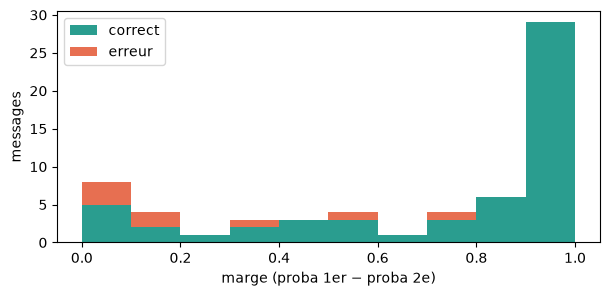

Marge médiane — correct : 0.918 | erreur : 0.125


In [6]:
plt.figure(figsize=(7, 3))
plt.hist([res[res.correct].marge, res[~res.correct].marge], bins=10, range=(0, 1), stacked=True,
         label=["correct", "erreur"], color=["#2a9d8f", "#e76f51"])
plt.xlabel("marge (proba 1er − proba 2e)"); plt.ylabel("messages"); plt.legend(); plt.show()
print("Marge médiane — correct :", res[res.correct].marge.median(), "| erreur :", res[~res.correct].marge.median())

## 5. Exercice : réécrire une option
Voici une variante où l'option *facturation* dit seulement **« Facturation : questions sur les factures »**. Elle ne parle plus des **débits / prélèvements**. Lançons-la :

In [7]:
rapport_ex, res_ex = at.evaluer(modele, dev, at.OPTIONS_EXERCICE)
print(f"Exactitude avec la variante : {res_ex.correct.mean():.1%}  ({res_ex.correct.sum()}/{len(res_ex)})")
res_ex[~res_ex.correct & (res_ex.label == "facturation")][["message", "prediction", "marge"]]

Durée estimée : ≈ 10 s pour 63 messages.


décisions:   0%|          | 0/63 [00:00<?, ?it/s]

63 messages évalués en 10.5 s (167 ms/message)
Exactitude avec la variante : 76.2%  (48/63)


,message,prediction,marge
9,Je veux un avoir pour les 5 jours sans internet de la semaine dernière,autre,0.019
13,"Bonsoir, le prélèvement a été rejeté par ma banque, je risque une coupure ? je peux pa...",resiliation,0.067
22,"vous m'avez débité 9,99€ pour une option streaming que j'ai jamais demandée",autre,0.352
30,"Le prélèvement de ce mois n'a pas eu lieu, est-ce normal ? Je ne veux pas avoir de fra...",livraison,0.277
34,"Prélèvement SEPA de 0,01 € ?? c'est quoi ce truc",autre,0.407
43,"Bonjour, double problème : ma box ne marche plus ET vous m'avez prélevé 2 fois. Commen...",technique,0.073
54,"jai recu un sms disant que mon paiement a échoué, mais la banque dit que tout est ok. ...",resiliation,0.097
55,J'ai été débité de 120 € pour le téléphone alors que je l'ai renvoyé sous 14 jours,livraison,0.052


**À vous !** Modifiez le texte de l'option `facturation` ci-dessous (ou une autre option qui vous semble mal écrite), puis exécutez la cellule. Règles du jeu :
- décrivez ce que l'option **couvre**, comme pour un collègue qui découvre le service ;
- utilisez les **mots des clients** (« prélevé », « débité », « remboursé ») ;
- n'ajoutez pas d'option « tout le reste / pas sûr » : elle aspire les messages.

In [8]:
mes_options = dict(at.OPTIONS_EXERCICE)
mes_options["facturation"] = "Facturation : questions sur les factures"   # <-- réécrivez ce texte
rapport_moi, res_moi = at.evaluer(modele, dev, mes_options)
print(f"Avant : {res_ex.correct.mean():.1%}   →   Après votre réécriture : {res_moi.correct.mean():.1%}")

Durée estimée : ≈ 10 s pour 63 messages.


décisions:   0%|          | 0/63 [00:00<?, ?it/s]

63 messages évalués en 10.4 s (165 ms/message)
Avant : 76.2%   →   Après votre réécriture : 76.2%


### Solution proposée (à dérouler après l'exercice)

In [9]:
solution = dict(at.OPTIONS_EXERCICE)
solution["facturation"] = ("Facturation et paiements : montant d'une facture, débits ou prélèvements bancaires, "
                           "remboursement, moyen ou date de paiement")
rapport_sol, res_sol = at.evaluer(modele, dev, solution)
comparaison = pd.DataFrame({"variante (factures seulement)": res_ex.set_index("id").prediction,
                            "solution (débits/prélèvements)": res_sol.set_index("id").prediction,
                            "référence": res_sol.set_index("id").label,
                            "message": res_sol.set_index("id").message})
changes = comparaison[comparaison.iloc[:, 0] != comparaison.iloc[:, 1]]
print(f"Variante : {res_ex.correct.mean():.1%}  →  solution : {res_sol.correct.mean():.1%}   ({len(changes)} messages ont changé de service)")
changes

Durée estimée : ≈ 10 s pour 63 messages.


décisions:   0%|          | 0/63 [00:00<?, ?it/s]

63 messages évalués en 10.4 s (165 ms/message)
Variante : 76.2%  →  solution : 87.3%   (8 messages ont changé de service)


,variante (factures seulement),solution (débits/prélèvements),référence,message
id,,,,
m151,resiliation,facturation,autre,"Bonjour, mon conjoint est décédé, je voudrais transférer le contrat à mon nom et que l..."
m006,resiliation,facturation,facturation,"Bonsoir, le prélèvement a été rejeté par ma banque, je risque une coupure ? je peux pa..."
m005,autre,facturation,facturation,"vous m'avez débité 9,99€ pour une option streaming que j'ai jamais demandée"
m013,livraison,facturation,facturation,"Le prélèvement de ce mois n'a pas eu lieu, est-ce normal ? Je ne veux pas avoir de fra..."
m032,autre,facturation,facturation,"Prélèvement SEPA de 0,01 € ?? c'est quoi ce truc"
m033,technique,facturation,facturation,"Bonjour, double problème : ma box ne marche plus ET vous m'avez prélevé 2 fois. Commen..."
m022,resiliation,facturation,facturation,"jai recu un sms disant que mon paiement a échoué, mais la banque dit que tout est ok. ..."
m024,livraison,facturation,facturation,J'ai été débité de 120 € pour le téléphone alors que je l'ai renvoyé sous 14 jours


### Contre-exemple : des libellés d'un mot + un attrape-tout

In [10]:
rapport_ft, res_ft = at.evaluer(modele, dev, at.OPTIONS_FOURRE_TOUT)
print(f"Libellés d'un mot + « Autre, pas sûr, tout le reste » : {res_ft.correct.mean():.1%}")
print("Prédictions :", res_ft.prediction.value_counts().to_dict())
print("Vérité      :", res_ft.label.value_counts().to_dict())

Durée estimée : ≈ 10 s pour 63 messages.


décisions:   0%|          | 0/63 [00:00<?, ?it/s]

63 messages évalués en 7.8 s (124 ms/message)
Libellés d'un mot + « Autre, pas sûr, tout le reste » : 65.1%
Prédictions : {'autre': 26, 'resiliation': 13, 'facturation': 10, 'livraison': 7, 'technique': 7}
Vérité      : {'technique': 16, 'facturation': 15, 'livraison': 12, 'autre': 11, 'resiliation': 9}


**À retenir** : le libellé d'une option *est* sa définition pour le modèle. On réécrit les options **sur dev**, jamais sur le test scellé.

---
**Étape 4, point de contrôle** (`missions/4_reparer_option/MISSION.md`) : le même objectif, à atteindre comme vous voulez (ce notebook, la commande `atelier`, ou un script).
Vérification sur dev : `atelier verifier 4` dans un terminal, ou la cellule ci-dessous.

In [11]:
from pathlib import Path
from atelier.missions import preparer, verifier
preparer(Path("../travail"))   # crée travail/ avec les fichiers de départ s'ils manquent (n'écrase rien)
print(verifier(4, globals().get("modele"), Path("../travail")).texte())   # réutilise le modèle déjà chargé

Étape 4 — Le libellé est la définition (bloc 4)
  ✅ les 5 identifiants de service : facturation, technique, resiliation, livraison, autre
  ❌ exactitude sur dev ≥ 85 % (76.2%, 48/63)
  ❌ au moins +5 points par rapport aux options de départ (76.2% → 76.2%)
  → erreur : « Bonjour, mon conjoint est décédé, je voudrais transférer le  » → resiliation (attendu autre, marge 0.58)
  → erreur : « Je voudrais passer mon contrat au nom de mon mari » → resiliation (attendu autre, marge 0.21)
  → erreur : « Je veux un avoir pour les 5 jours sans internet de la semain » → autre (attendu facturation, marge 0.02)
  → erreur : « Le contrôle parental ne bloque rien du tout, mes enfants acc » → autre (attendu technique, marge 0.03)
  → erreur : « Bonsoir, le prélèvement a été rejeté par ma banque, je risqu » → resiliation (attendu facturation, marge 0.07)
  Pas encore : relisez les indices de MISSION.md, un à la fois (1, puis 2, puis 3).
